In [10]:
import sys
sys.path.insert(0, "..")  # repository root, so `import km5c` works
import cartopy.crs as ccrs
import numpy as np
import pandas as pd

from km5c.plotting import place_point_labels
from km5c.transects import cumulative_distance_km, project_points_to_transect, wrap_longitude_180
from km5c.paths import FIG_DIR
from km5c.proxies import comparison_tables

proxy = comparison_tables()
PLIOMIP2_d13C_comparison_table = proxy.PLIOMIP2_d13C_comparison_table
PLIOMIP2_d18O_comparison_table = proxy.PLIOMIP2_d18O_comparison_table


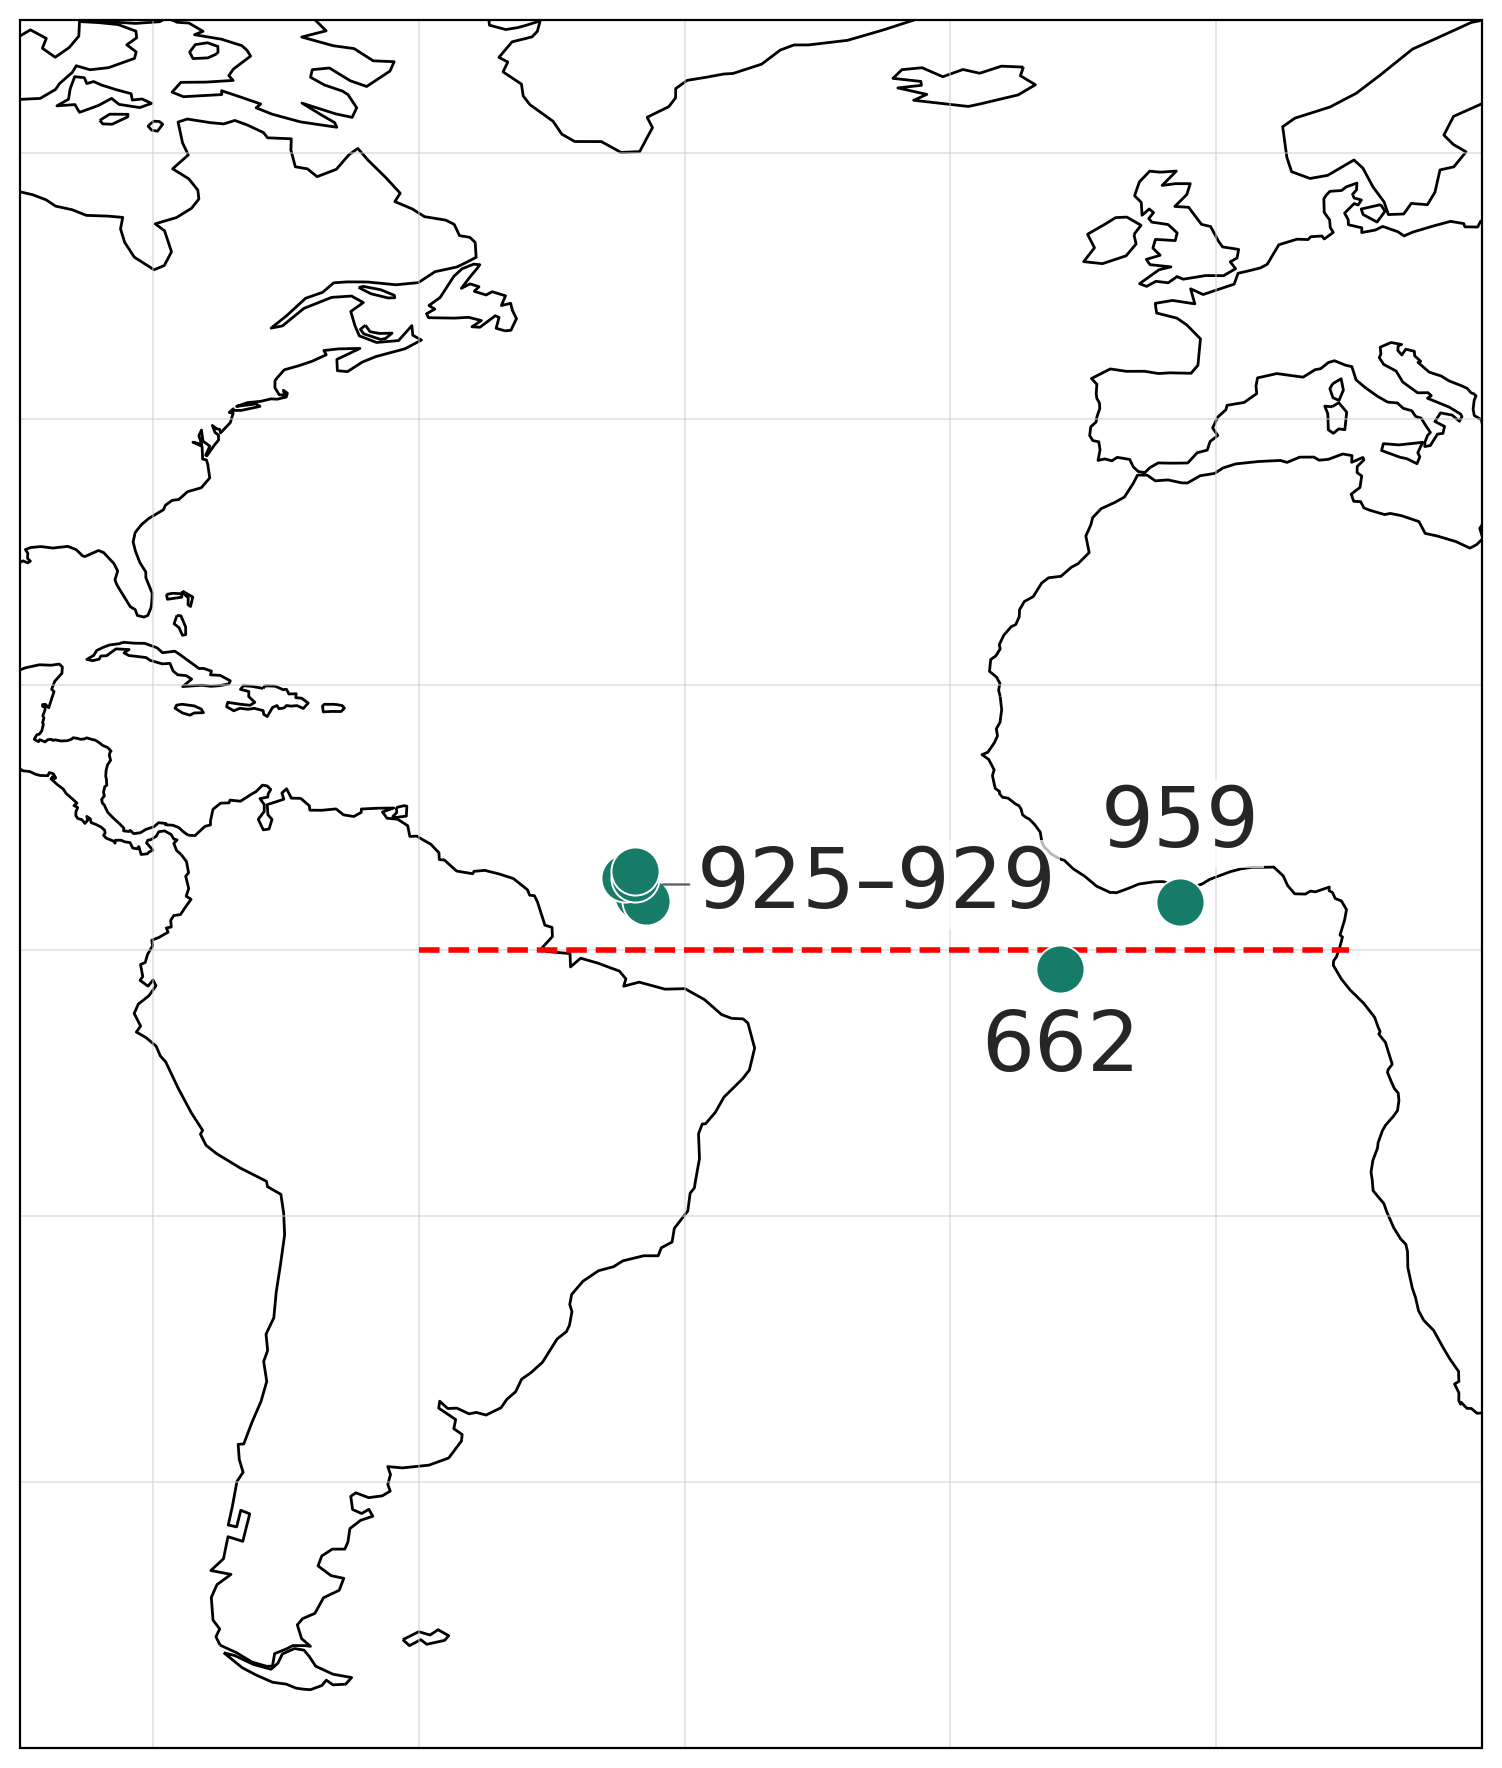

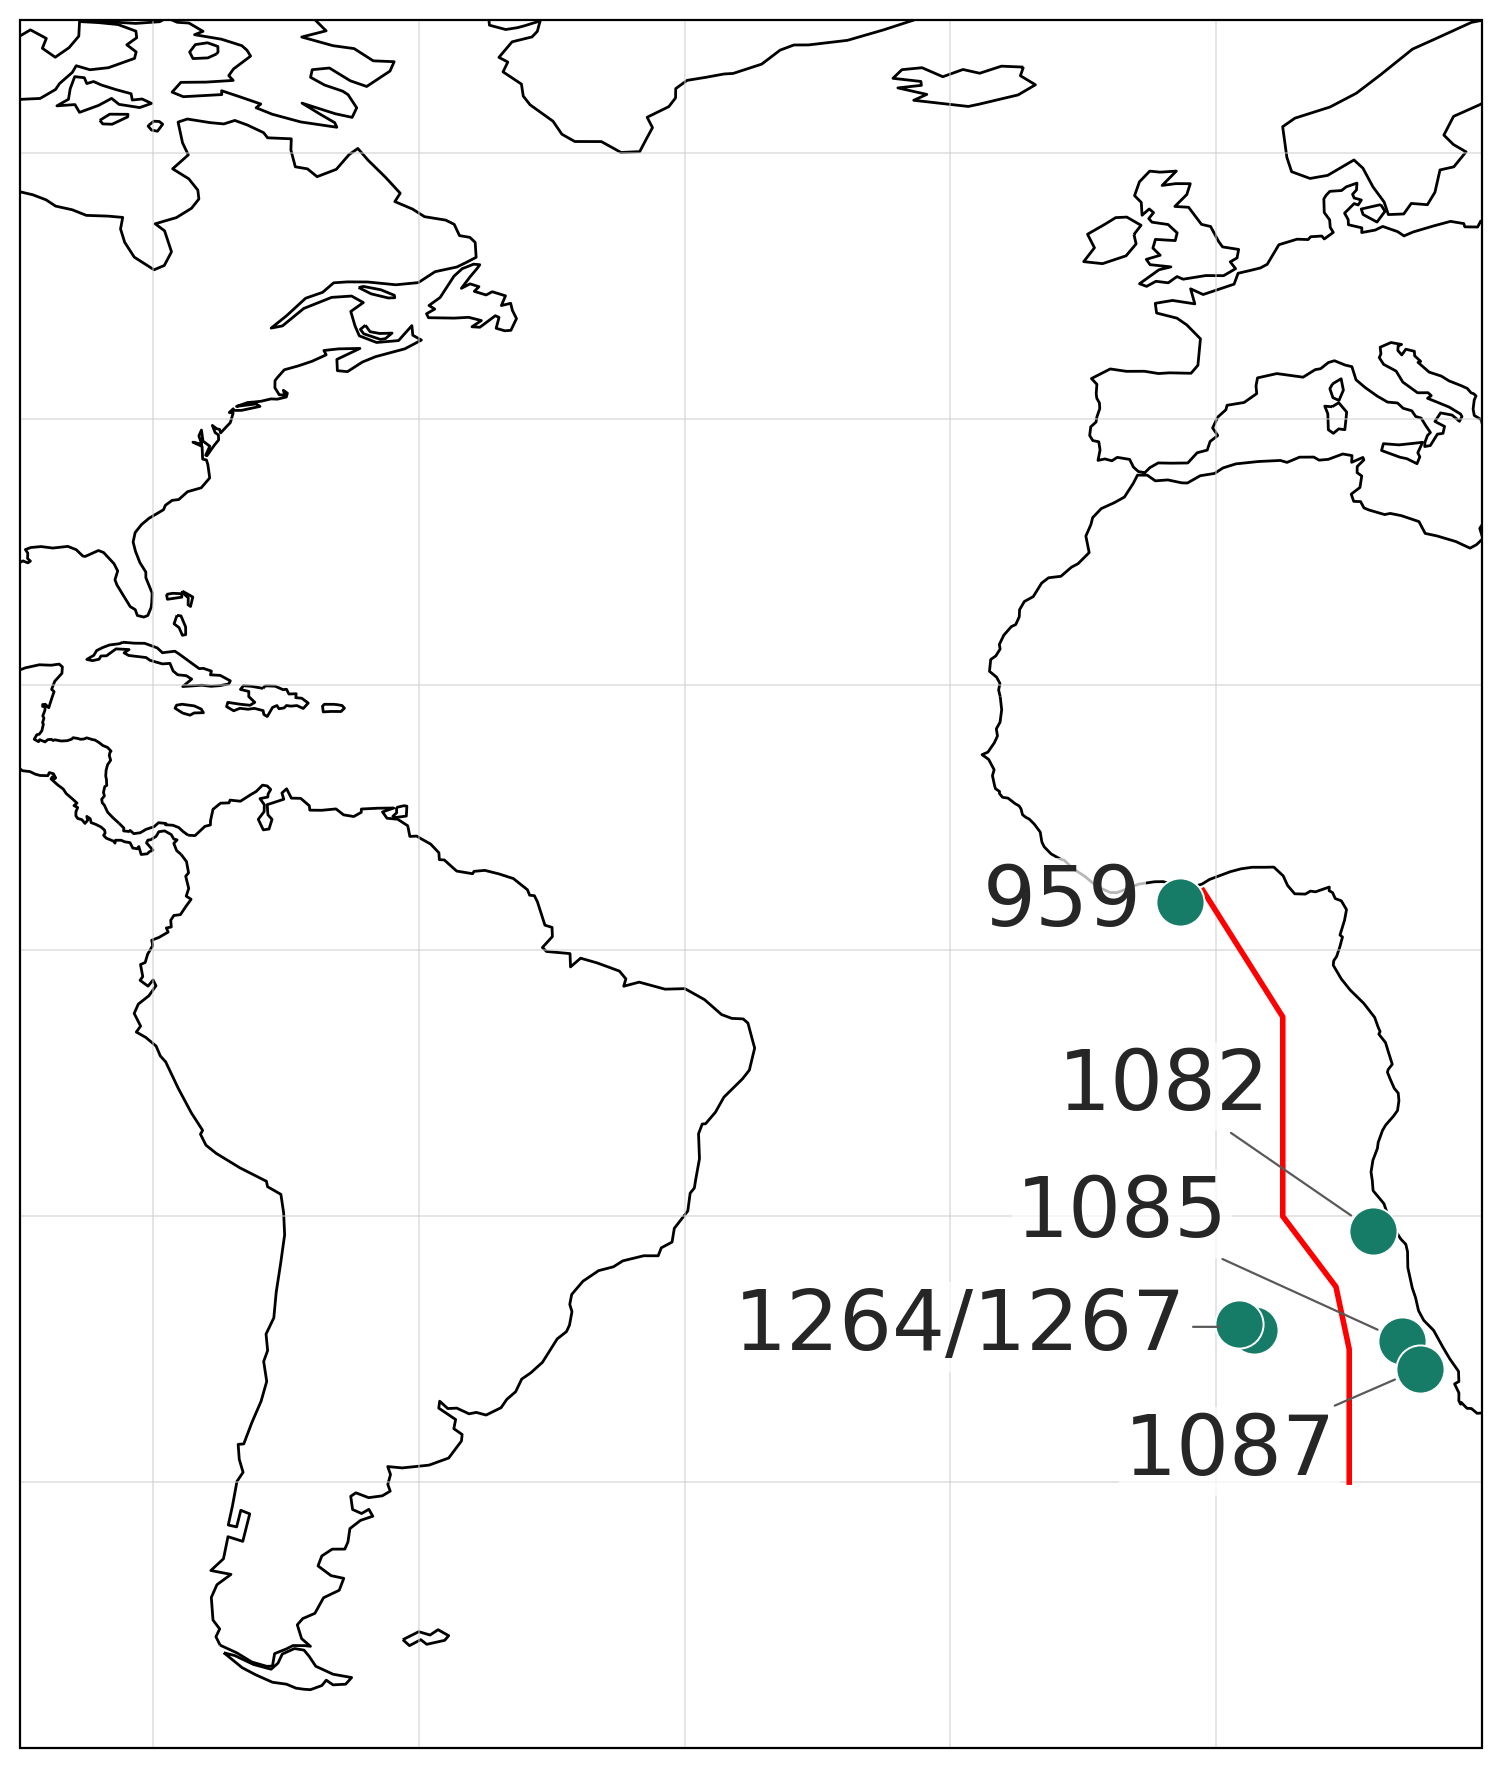

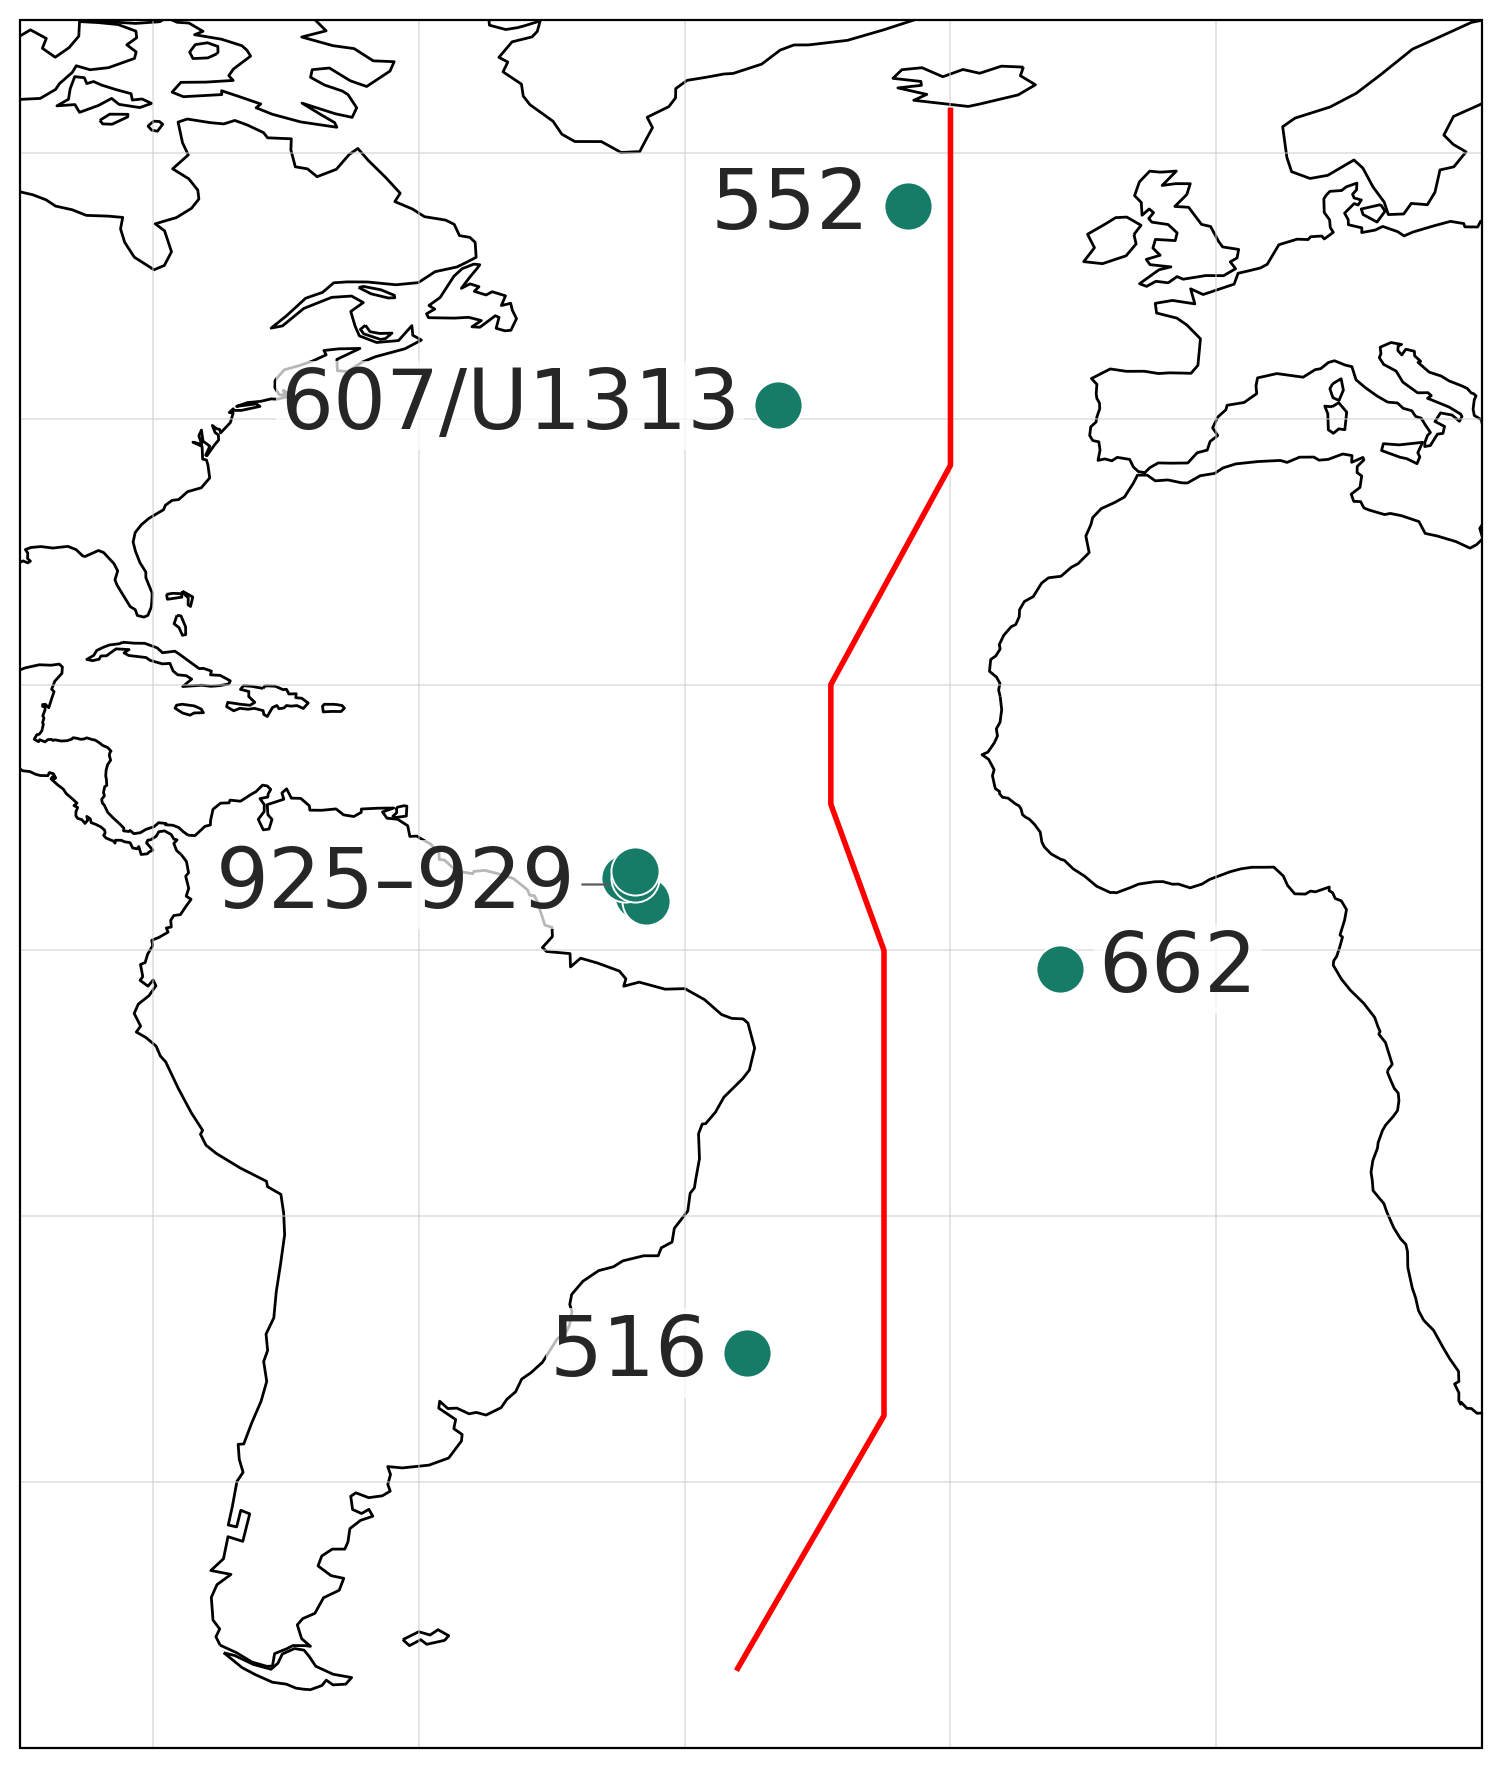

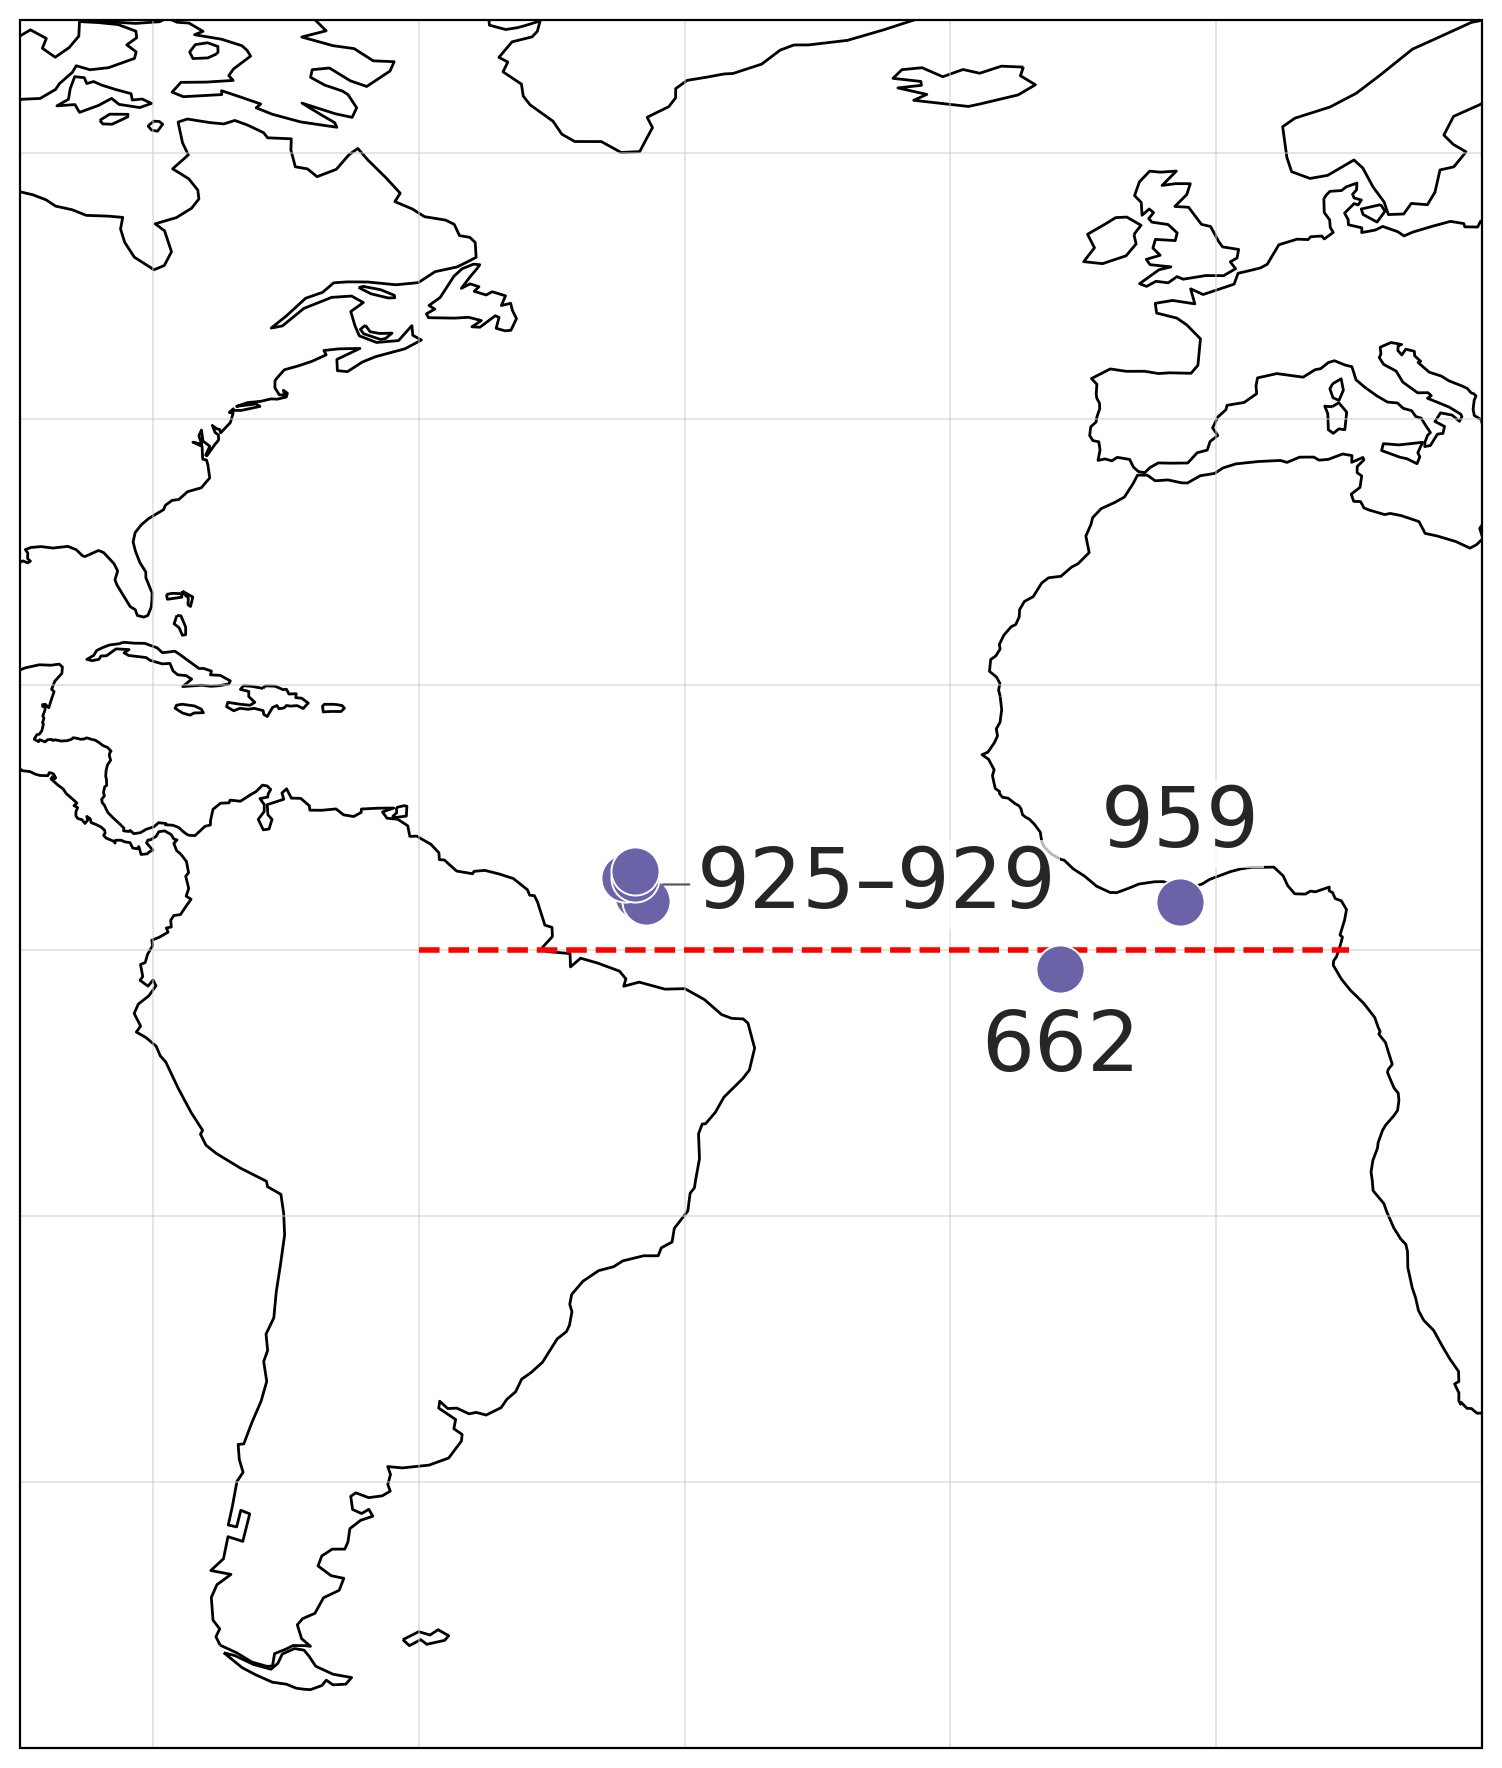

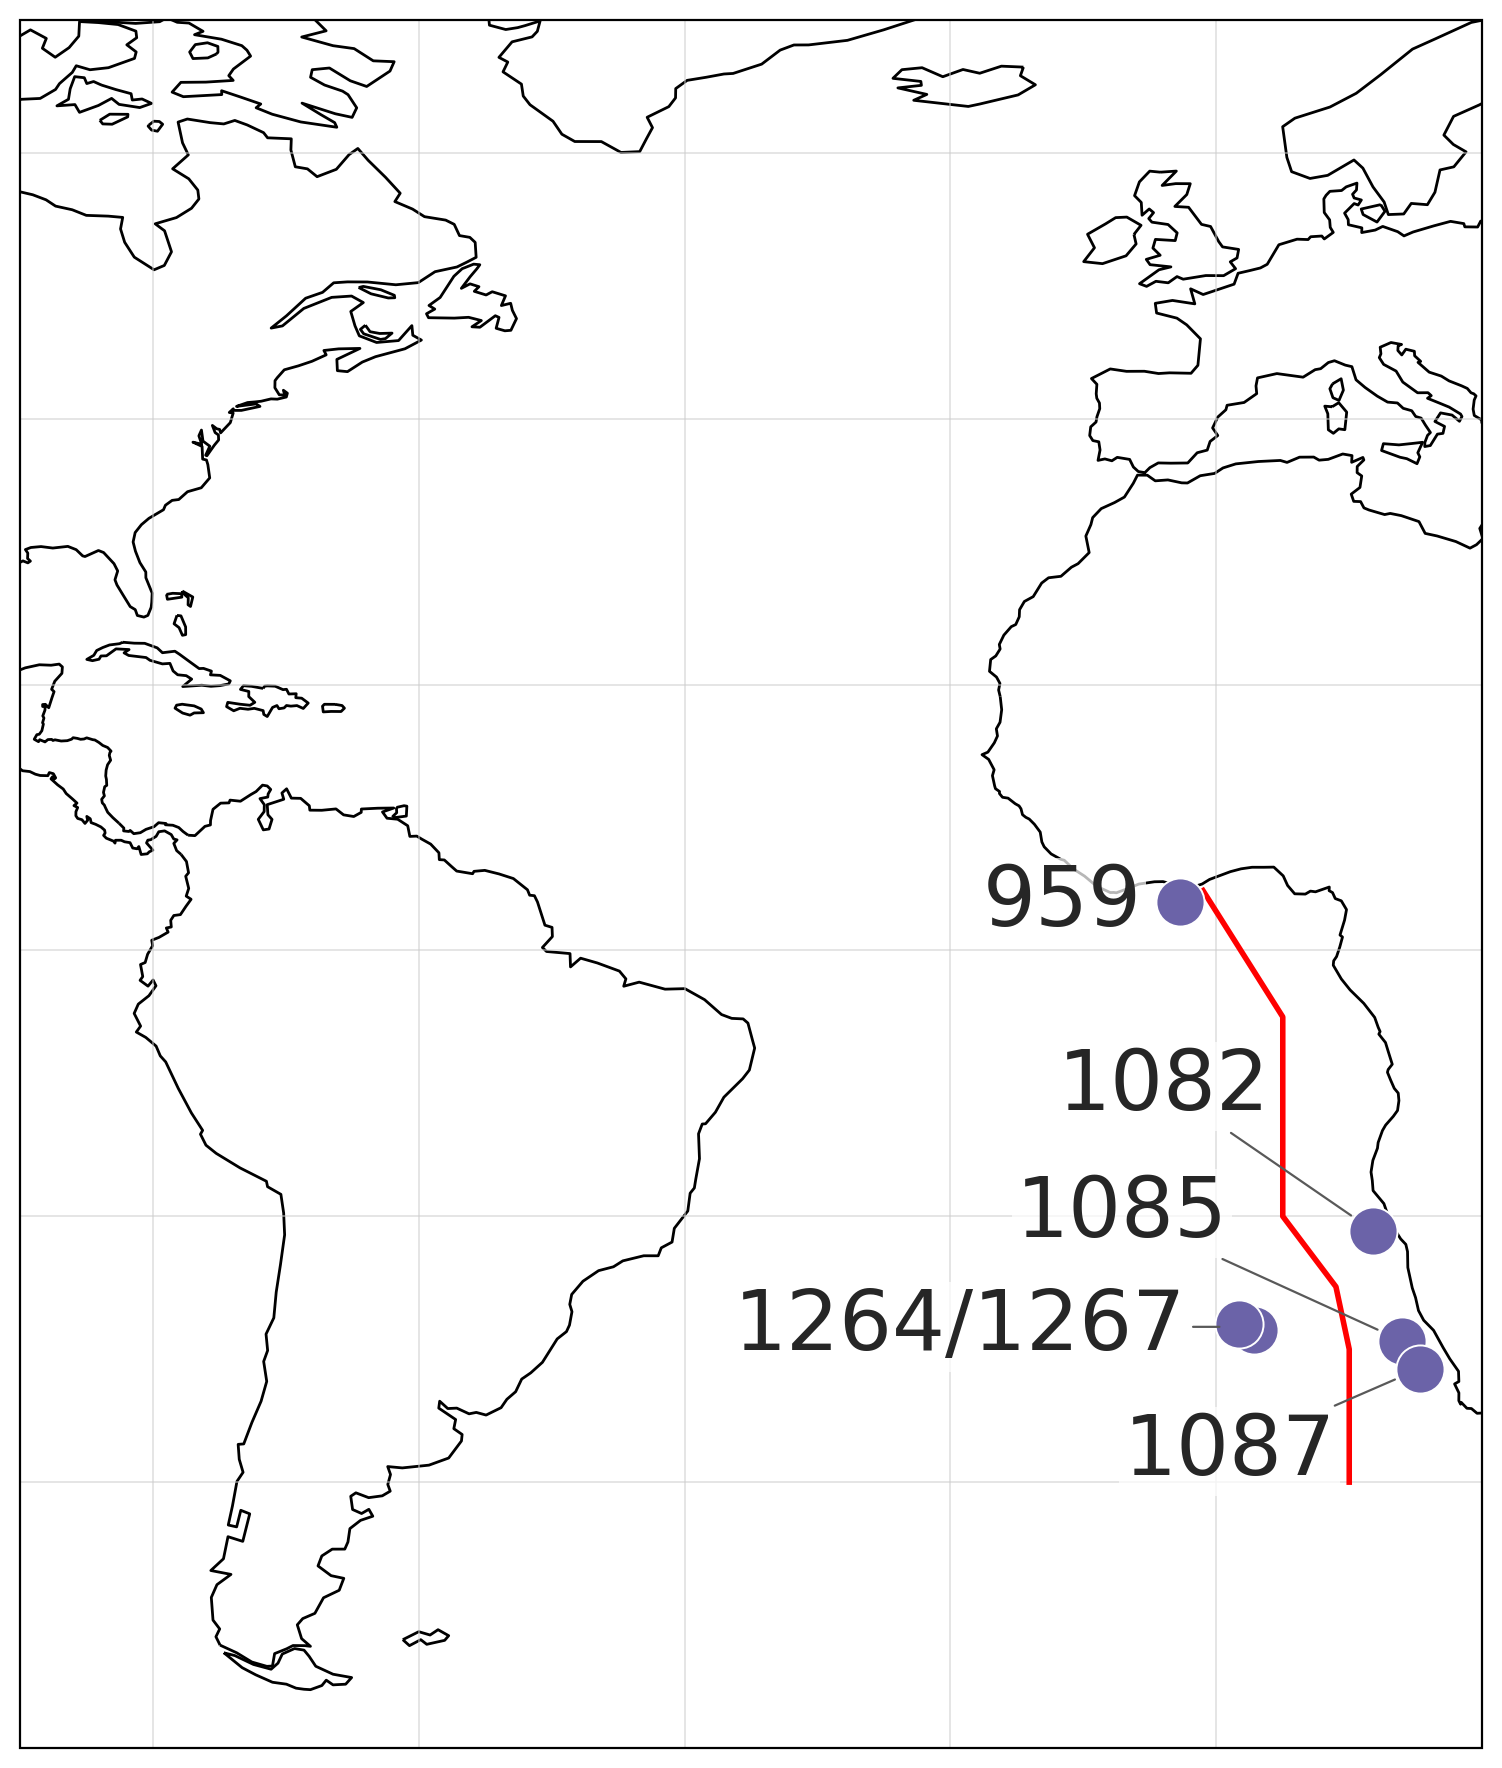

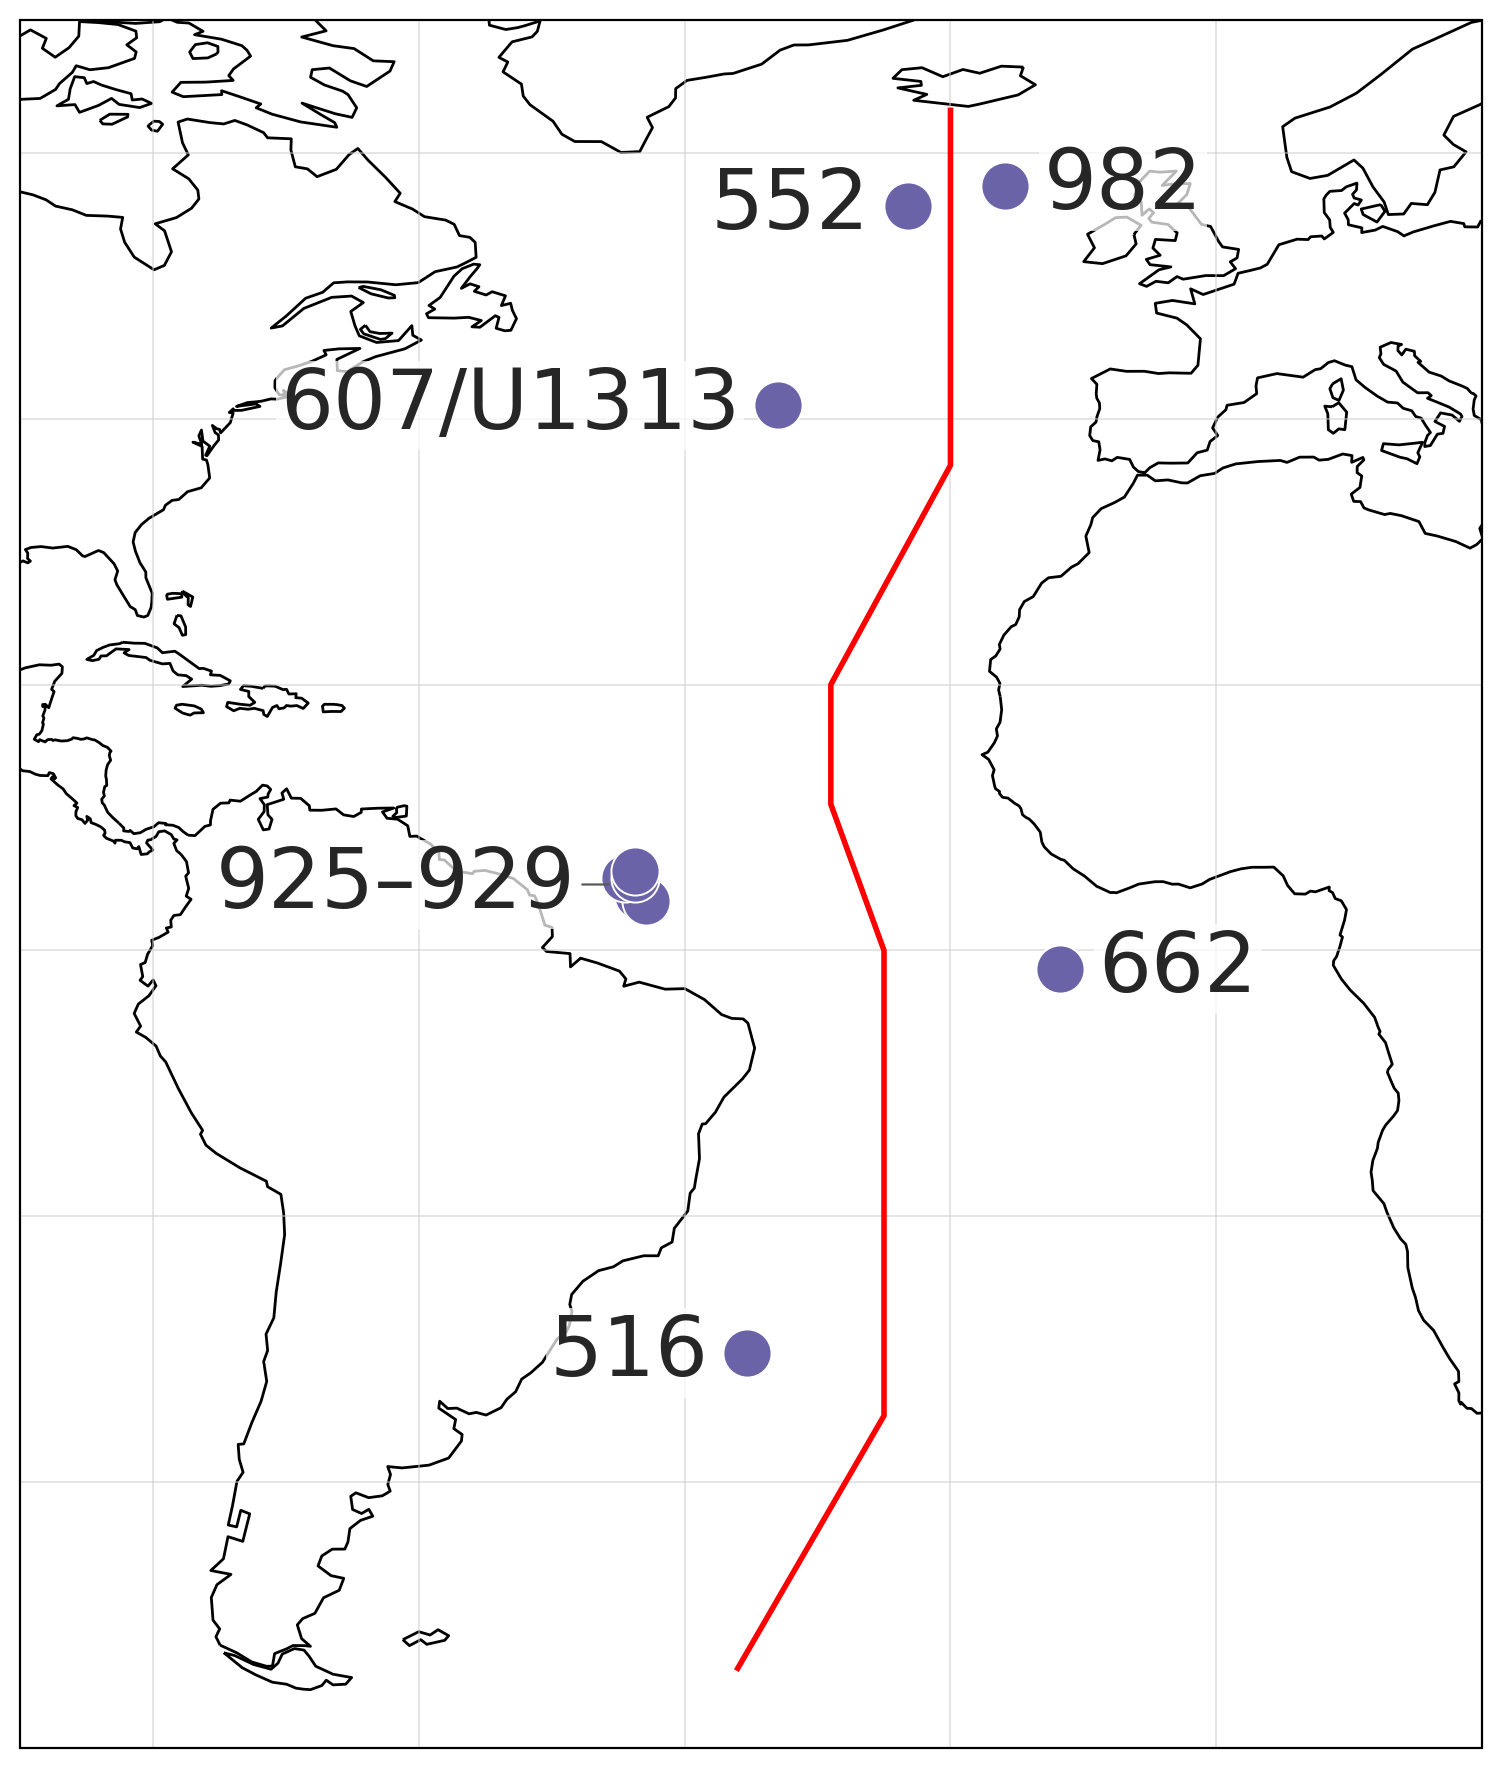

: 

In [ ]:
import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams.update(mpl.rcParamsDefault)
plt.rcdefaults()
mpl.rcParams.update({
    "font.size": 10,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
})

# Transect geometry shared with d13C_transects.ipynb and d18O_transects.ipynb.
A13_line_lon = [10, 10, 9, 5, 5, -1]
A13_line_lat = [-40, -30, -25.3, -20, -5, 4.5]
A16_line_lon = [-36, -25, -25, -29, -29, -20, -20]
A16_line_lat = [-54, -35, 0, 11, 20, 36.5, 63.2]

box_lat_min, box_lat_max = -10.5, 10.5
box_lon_min, box_lon_max = -60, 10


def setup_atlantic_map(ax):
    ax.set_extent([-90, 20, -60, 70], crs=ccrs.PlateCarree())
    ax.set_xticks([])
    ax.set_yticks([])
    ax.coastlines()
    ax.gridlines(
        crs=ccrs.PlateCarree(),
        draw_labels=False,
        xlocs=np.arange(-80, 21, 20),
        ylocs=np.arange(-60, 61, 20),
        linewidth=0.6,
        color="0.8",
        alpha=0.6,
        linestyle="-",
    )


def select_plotted_sites(comparison_table, isotope_column):
    """Mirror the point selection used by the isotope transect notebook."""
    points = comparison_table.copy()
    points = points[points["Site name"].astype(str).str.lower() != "average"].copy()
    for column in ["Longitude", "Latitude", "Water depth (m)", isotope_column]:
        points[column] = pd.to_numeric(points[column], errors="coerce")
    points = points.dropna(
        subset=["Longitude", "Latitude", "Water depth (m)", isotope_column]
    ).copy()
    points["Longitude_wrapped"] = ((points["Longitude"] + 180) % 360) - 180

    equator = points[
        points["Latitude"].between(box_lat_min, box_lat_max)
        & points["Longitude_wrapped"].between(box_lon_min, box_lon_max)
        & points["Water depth (m)"].between(200, 5380)
    ].copy()

    # Match the transect notebooks' existing path projection and longitude window.
    a13 = project_points_to_transect(
        points, A13_line_lon, A13_line_lat, isotope_column,
        longitude_window_deg=10.0,
    )
    if not a13.empty:
        a13 = a13[a13["depth_m"].between(200, 5380)].copy()
        # Keep only sites inside the A13 transect panels' x-range (0 to the end of the line);
        # sites south of the line's 40S end project to negative distances and aren't plotted there.
        a13_length_km = cumulative_distance_km(wrap_longitude_180(A13_line_lon), A13_line_lat)[-1]
        a13 = a13[a13["distance_km"].between(0, a13_length_km)].copy()
    a16 = project_points_to_transect(
        points, A16_line_lon, A16_line_lat, isotope_column,
        longitude_window_deg=10.0,
    )
    if not a16.empty:
        a16 = a16[a16["depth_m"].between(200, 5380)].copy()
    return {"equator": equator, "A13": a13, "A16": a16}


def format_site_label(value):
    text = str(value).strip()
    try:
        number = float(text)
        if np.isfinite(number) and number.is_integer():
            return str(int(number))
    except (TypeError, ValueError):
        pass
    return text


isotope_specs = [
    {
        "code": "d13C",
        "label": r"$\delta^{13}\mathrm{C}$",
        "column": "PLIOMIP2 d13C",
        "table": PLIOMIP2_d13C_comparison_table,
        "color": "#167c68",
    },
    {
        "code": "d18O",
        "label": r"$\delta^{18}\mathrm{O}$",
        "column": "PLIOMIP2 d18O",
        "table": PLIOMIP2_d18O_comparison_table,
        "color": "#6b63a8",
    },
]
map_rows = [
    {"key": "equator", "label": "Equatorial band", "geometry": "equator"},
    {"key": "A13", "label": "A13 transect", "geometry": "A13"},
    {"key": "A16", "label": "A16 transect", "geometry": "A16"},
]
LABEL_FONTSIZE = 30

from pathlib import Path

output_dir = FIG_DIR
output_dir.mkdir(parents=True, exist_ok=True)
map_figures = {}
map_site_counts = {}
map_output_paths = {}

for isotope in isotope_specs:
    selected_by_panel = select_plotted_sites(isotope["table"], isotope["column"])
    for panel in map_rows:
        fig, ax = plt.subplots(
            figsize=(8, 9), dpi=200,
            subplot_kw={"projection": ccrs.PlateCarree()},
        )
        setup_atlantic_map(ax)
        if panel["geometry"] == "equator":
            ax.plot(
                [box_lon_min, box_lon_max], [0, 0],
                color="red", linewidth=2.0, linestyle="--",
                transform=ccrs.PlateCarree(), zorder=4,
            )
        elif panel["geometry"] == "A13":
            ax.plot(
                A13_line_lon, A13_line_lat,
                color="red", linewidth=2.0, linestyle="-",
                transform=ccrs.PlateCarree(), zorder=4,
            )
        else:
            ax.plot(
                A16_line_lon, A16_line_lat,
                color="red", linewidth=2.0, linestyle="-",
                transform=ccrs.PlateCarree(), zorder=4,
            )

        fig.subplots_adjust(left=0.03, right=0.97, top=0.98, bottom=0.02)
        selected = selected_by_panel[panel["key"]]
        if not selected.empty:
            # Keep one map label per distinct site location, even if source rows repeat it.
            sites = selected.drop_duplicates(
                subset=["Site name", "Longitude_wrapped", "Latitude"]
            ).reset_index(drop=True)
            ax.scatter(
                sites["Longitude_wrapped"], sites["Latitude"],
                s=300, marker="o", color=isotope["color"],
                edgecolors="white", linewidths=0.7,
                transform=ccrs.PlateCarree(), zorder=6,
            )
            transect = {
                "equator": ([box_lon_min, box_lon_max], [0, 0]),
                "A13": (A13_line_lon, A13_line_lat),
                "A16": (A16_line_lon, A16_line_lat),
            }[panel["geometry"]]
            # Labels sit next to their point where there is room; otherwise further out with a leader line.
            place_point_labels(
                ax,
                sites["Longitude_wrapped"].to_numpy(dtype=float),
                sites["Latitude"].to_numpy(dtype=float),
                [format_site_label(name) for name in sites["Site name"]],
                transform=ccrs.PlateCarree()._as_mpl_transform(ax),
                fontsize=LABEL_FONTSIZE,
                marker_size=300,
                avoid_lines=[transect],
                pad=4,
                merge_overlapping=[{"607", "U1313"}],  # only these two share a label
                text_kw={"bbox": {"facecolor": "white", "edgecolor": "none", "alpha": 0.72, "pad": 1.5}},
            )
            site_count = len(sites)
        else:
            site_count = 0


        figure_key = (isotope["code"], panel["key"])
        output_path = output_dir / f"maps_{isotope['code']}_{panel['key']}.png"
        fig.savefig(output_path, dpi=300, facecolor="white")
        map_figures[figure_key] = fig
        map_site_counts[figure_key] = site_count
        map_output_paths[figure_key] = str(output_path.resolve())
        plt.show()
